In [13]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.signal import savgol_filter


# ==========================================
# 1. VERBETERDE HELPER FUNCTIE VOOR INLEZEN CSV
# ==========================================
def load_lab_csv(filepath):
  """Leest laboratorium CSV-bestanden in en filtert automatisch de kopteksten eruit."""
  values = []
  with open(filepath, 'r') as f:
    for line in f:
      line_str = line.strip()
      if not line_str:
        continue
      # Probeer de regel rechtstreeks als getal in te lezen
      try:
        val = float(line_str)
        values.append(val)
      except ValueError:
        # Als er scheidingstekens staan, pak de eerste numerieke waarde
        parts = line_str.replace('\t', ',').split(',')
        try:
          val = float(parts[0])
          values.append(val)
        except ValueError:
          pass  # Sla kopteksten zoals 'Data info', 'Units', etc. automatisch over

  return np.array(values)


# ==========================================
# 2. PT1000 KALIBRATIE
# ==========================================
R_pt1000_77K = 197.6  # Gemeten Pt1000 weerstand bij 77 K (Ohm)[cite: 16]
R_pt1000_294K = 1088.0  # Gemeten Pt1000 weerstand bij 294 K (Ohm)[cite: 16]

a_cal = (291.0 - 77.0) / (R_pt1000_294K - R_pt1000_77K)
b_cal = 77.0 - a_cal * R_pt1000_77K


def pt1000_to_kelvin(R_sensor):
  return a_cal * R_sensor + b_cal


I_source = 0.1  # Keithley SMU bronstroom (0.1 A)[cite: 16, 19]

# ==========================================
# 3. DATA INLEZEN EN VERWERKEN (METINGEN 1 t/m 5)
# ==========================================
summary_data = []

for i in range(1, 13):
  smu_file = f'SMUdata_pt1000_{i}.csv'
  dmm_file = f'DMMdata_pt1000_{i}.csv'

  if not (os.path.exists(smu_file) and os.path.exists(dmm_file)):
    print(f'Bestand niet gevonden: {smu_file} of {dmm_file}')
    continue

  # Inlezen met de robuuste functie
  R_pt1000_raw = load_lab_csv(dmm_file)
  V_raw = load_lab_csv(smu_file)

  if len(R_pt1000_raw) == 0 or len(V_raw) == 0:
    print(f'Geen geldige data gevonden in {smu_file} of {dmm_file}')
    continue

  # ==========================================
  # 4. VERWERKING & Tc BEPALING
  # ==========================================
  T_data = pt1000_to_kelvin(R_pt1000_raw)
  R_bscco = V_raw / I_source

  # Sorteren op stijgende temperatuur
  sort_idx = np.argsort(T_data)
  T_clean = T_data[sort_idx]
  R_clean = R_bscco[sort_idx]

  # Ruisfiltering & Spline Fit
  window_len = (
      15
      if len(R_clean) >= 15
      else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
  )
  R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

  spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
  T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
  R_fit = spline(T_fine)
  dR_dT = spline.derivative(n=1)(T_fine)

  # Buigpunt & Tc Extrapolatie[cite: 20]
  idx_max = np.argmax(dR_dT)
  T_inflection = T_fine[idx_max]
  R_inflection = R_fit[idx_max]
  m_max = dR_dT[idx_max]

  R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
  Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

  summary_data.append({
      'Meting': f'Meting {i}',
      'Buigpunt (K)': round(T_inflection, 2),
      'Max Helling (mOhm/K)': round(m_max * 1000, 3),
      'Gextrapoleerde Tc (K)': round(Tc_extrapolated, 2),
  })

  print(
      f'Meting {i} -> Buigpunt: {T_inflection:.2f} K | Gextrapoleerde Tc:'
      f' {Tc_extrapolated:.2f} K'
  )

# ==========================================
# 5. OVERZICHTSTABEL PRINTEN
# ==========================================
if summary_data:
  df_summary = pd.DataFrame(summary_data)
  print('\n=======================================================')
  print('          RESULTATEN METINGEN 1 t/m 5                  ')
  print('=======================================================')
  print(df_summary.to_string(index=False))

Meting 1 -> Buigpunt: 77.16 K | Gextrapoleerde Tc: 77.17 K
Meting 2 -> Buigpunt: 110.13 K | Gextrapoleerde Tc: 110.04 K
Meting 3 -> Buigpunt: 103.82 K | Gextrapoleerde Tc: 101.26 K
Meting 4 -> Buigpunt: 104.60 K | Gextrapoleerde Tc: 101.81 K
Meting 5 -> Buigpunt: 104.60 K | Gextrapoleerde Tc: 101.81 K
Meting 6 -> Buigpunt: 76.97 K | Gextrapoleerde Tc: 76.97 K
Meting 7 -> Buigpunt: 101.10 K | Gextrapoleerde Tc: 98.21 K
Meting 8 -> Buigpunt: 101.52 K | Gextrapoleerde Tc: 99.99 K
Meting 9 -> Buigpunt: 108.72 K | Gextrapoleerde Tc: 105.80 K
Meting 10 -> Buigpunt: 105.19 K | Gextrapoleerde Tc: 102.91 K
Meting 11 -> Buigpunt: 103.00 K | Gextrapoleerde Tc: 100.22 K
Bestand niet gevonden: SMUdata_pt1000_12.csv of DMMdata_pt1000_12.csv

          RESULTATEN METINGEN 1 t/m 5                  
   Meting  Buigpunt (K)  Max Helling (mOhm/K)  Gextrapoleerde Tc (K)
 Meting 1         77.16                19.528                  77.17
 Meting 2        110.13               338.638                 110.04

In [20]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.signal import savgol_filter


# ==========================================
# 1. HELPER FUNCTIE VOOR INLEZEN CSV
# ==========================================
def load_lab_csv(filepath):
  """Leest laboratorium CSV-bestanden in en filtert tekst-/kopregels automatisch uit."""
  values = []
  with open(filepath, 'r') as f:
    for line in f:
      line_str = line.strip()
      if not line_str:
        continue
      try:
        val = float(line_str)
        values.append(val)
      except ValueError:
        parts = line_str.replace('\t', ',').split(',')
        try:
          val = float(parts[0])
          values.append(val)
        except ValueError:
          pass
  return np.array(values)


# ==========================================
# 2. PT1000 KALIBRATIE
# ==========================================
R_pt1000_77K = 197.6  # Gemeten Pt1000 weerstand bij 77 K (Ohm)
R_pt1000_294K = 1088.0  # Gemeten Pt1000 weerstand bij 294 K (Ohm)

a_cal = (291.0 - 77.0) / (R_pt1000_294K - R_pt1000_77K)
b_cal = 77.0 - a_cal * R_pt1000_77K


def pt1000_to_kelvin(R_sensor):
  return a_cal * R_sensor + b_cal


I = 0.1  # Keithley SMU stroomsterkte I = 0.1 A

# ==========================================
# 3. VERWERKING MET EXPLICITE FORMULE (4.4)
# ==========================================
summary_data = []

for i in range(1, 13):
  smu_file = f'SMUdata_pt1000_{i}.csv'
  dmm_file = f'DMMdata_pt1000_{i}.csv'

  if not (os.path.exists(smu_file) and os.path.exists(dmm_file)):
    continue

  R_pt1000_raw = load_lab_csv(dmm_file)
  V_raw = load_lab_csv(smu_file)

  if len(R_pt1000_raw) == 0 or len(V_raw) == 0:
    continue

  # Maak even aantal meetpunten voor paarsgewijze verwerking
  if len(V_raw) % 2 != 0:
    min_len = (len(V_raw) // 2) * 2
    V_raw = V_raw[:min_len]
    R_pt1000_raw = R_pt1000_raw[:min_len]

  # V_M+ meting bij +0.1 A en V_M- meting bij -0.1 A
  V_M_pos = V_raw[0::2]  # V_M+
  V_M_neg = V_raw[1::2]  # V_M-

  # Gemiddelde Pt1000 sensorweerstand per paar
  R_pt1000_pairs = (R_pt1000_raw[0::2] + R_pt1000_raw[1::2]) / 2.0

  # -------------------------------------------------------------------
  # FORMULE (4.4) UIT DE HANDLEIDING:
  # V_M = (V_M+ - V_M-) / 2 = I * R
  # -------------------------------------------------------------------
  V_M = (V_M_pos - V_M_neg) / 2.0  # Gecorrigeerde spanning zonder V_EMF
  R_bscco = V_M / I  # Monsterweerstand R = V_M / I

  # Thermoelektrische offsetspanning V_EMF ter controle
  V_EMF = (V_M_pos + V_M_neg) / 2.0

  # Omrekenen naar Kelvin
  T_data = pt1000_to_kelvin(R_pt1000_pairs)

  # -------------------------------------------------------------------
  # SORTEREN, SMOOTHEN & T_C BEPALING
  # -------------------------------------------------------------------
  sort_idx = np.argsort(T_data)
  T_clean = T_data[sort_idx]
  R_clean = R_bscco[sort_idx]

  window_len = (
      15
      if len(R_clean) >= 15
      else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
  )
  R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

  spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
  T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
  R_fit = spline(T_fine)
  dR_dT = spline.derivative(n=1)(T_fine)

  idx_max = np.argmax(dR_dT)
  T_inflection = T_fine[idx_max]
  R_inflection = R_fit[idx_max]
  m_max = dR_dT[idx_max]

  R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
  Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

  summary_data.append({
      'Meting': f'Meting {i}',
      'Gem. V_EMF (uV)': round(np.mean(V_EMF) * 1e6, 2),
      'Buigpunt (K)': round(T_inflection, 2),
      'Max Helling (mOhm/K)': round(m_max * 1000, 3),
      'Gextrapoleerde Tc (K)': round(Tc_extrapolated, 2),
  })

# ==========================================
# 4. OVERZICHTSTABEL PRINTEN
# ==========================================
if summary_data:
  df_summary = pd.DataFrame(summary_data)
  print('\n=======================================================')
  print('     RESULTATEN MET FORMULE 4.4 (V_M EN V_EMF)         ')
  print('=======================================================')
  print(df_summary.to_string(index=False))


     RESULTATEN MET FORMULE 4.4 (V_M EN V_EMF)         
   Meting  Gem. V_EMF (uV)  Buigpunt (K)  Max Helling (mOhm/K)  Gextrapoleerde Tc (K)
 Meting 1           704.86        115.22                 0.666                 115.23
 Meting 2           158.28        108.90                91.162                 108.79
 Meting 3           382.68        128.92                 0.005                 125.96
 Meting 4           337.15        117.91                 0.007                 117.49
 Meting 5           337.15        117.91                 0.007                 117.49
 Meting 6           427.32        134.71                 0.002                 139.24
 Meting 7           315.81        125.52                 0.005                 122.57
 Meting 8           282.33        120.95                 0.004                 119.38
 Meting 9           305.81        128.51                 0.004                 126.35
Meting 10           327.54        123.82                 0.005                 121.

<>:178: SyntaxWarning: invalid escape sequence '\ '
<>:178: SyntaxWarning: invalid escape sequence '\O'
<>:205: SyntaxWarning: invalid escape sequence '\O'
<>:206: SyntaxWarning: invalid escape sequence '\O'
<>:208: SyntaxWarning: invalid escape sequence '\ '
<>:178: SyntaxWarning: invalid escape sequence '\ '
<>:178: SyntaxWarning: invalid escape sequence '\O'
<>:205: SyntaxWarning: invalid escape sequence '\O'
<>:206: SyntaxWarning: invalid escape sequence '\O'
<>:208: SyntaxWarning: invalid escape sequence '\ '
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\1510873863.py:178: SyntaxWarning: invalid escape sequence '\ '
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\1510873863.py:178: SyntaxWarning: invalid escape sequence '\O'
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\1510873863.py:205: SyntaxWarning: invalid escape sequence '\O'
  ax1.set

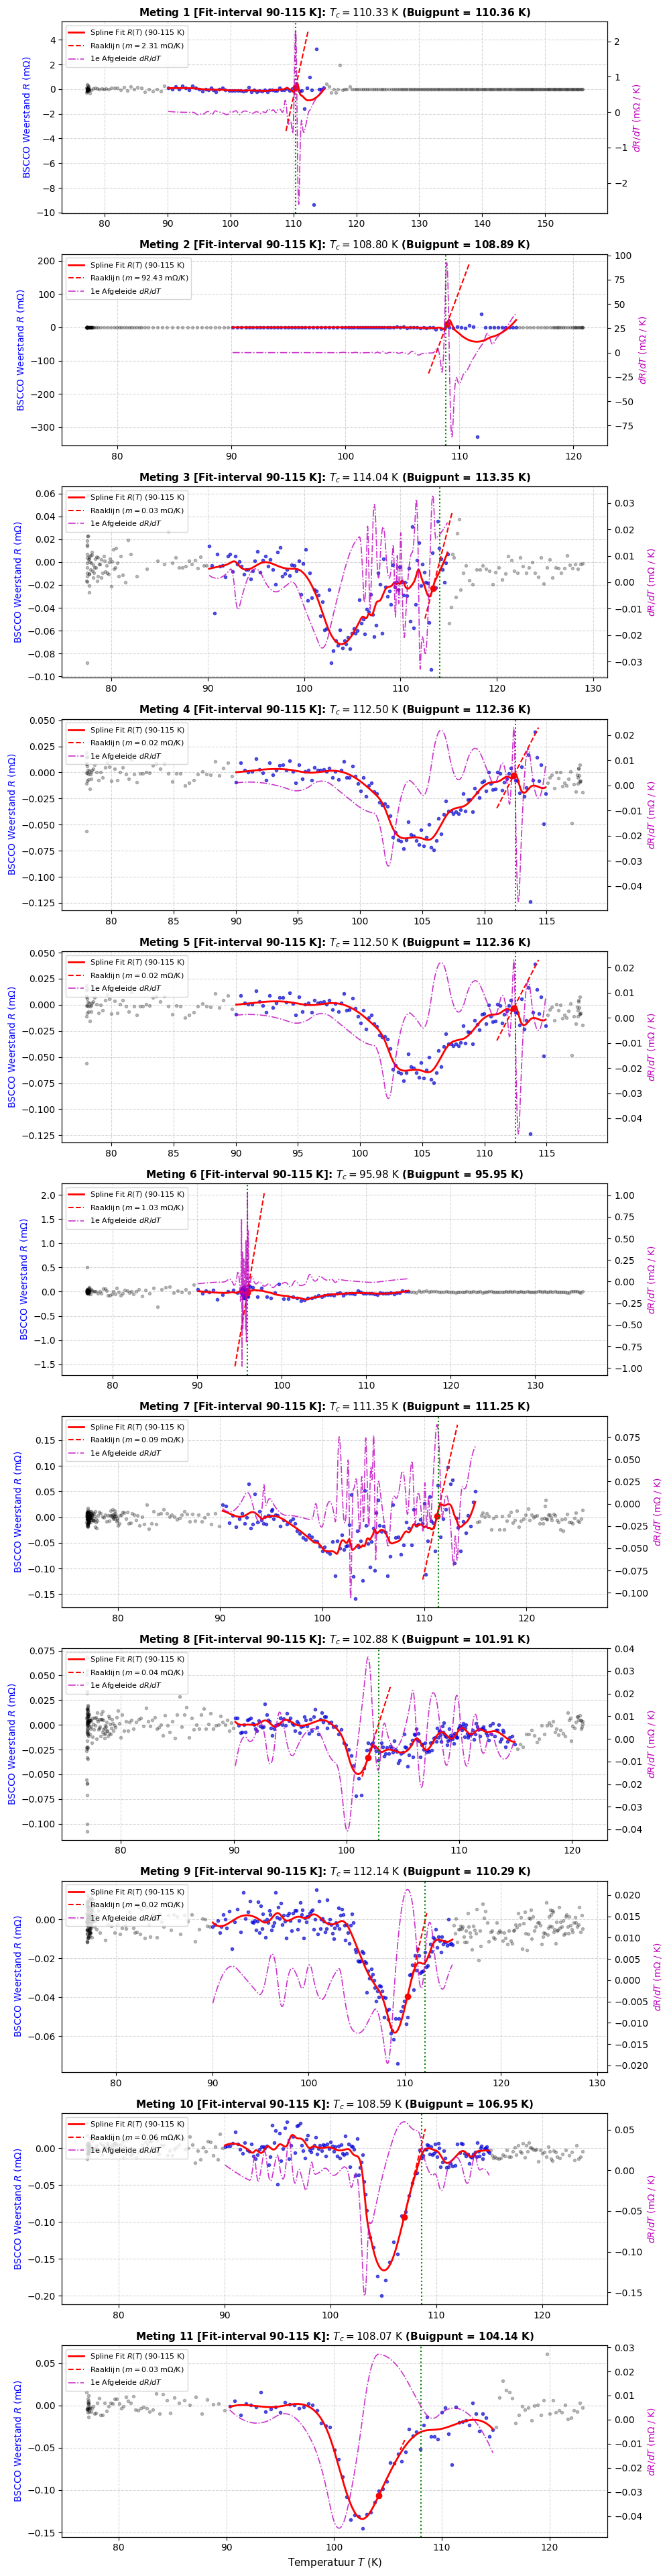


     RESULTATEN MET SPLINE FIT [90 K T/M 115 K]        
   Meting  Buigpunt (K)  Max Helling (mOhm/K)  Gextrapoleerde Tc (K)
 Meting 1        110.36                 2.308                 110.33
 Meting 2        108.89                92.434                 108.80
 Meting 3        113.35                 0.033                 114.04
 Meting 4        112.36                 0.023                 112.50
 Meting 5        112.36                 0.023                 112.50
 Meting 6         95.95                 1.034                  95.98
 Meting 7        111.25                 0.089                 111.35
 Meting 8        101.91                 0.036                 102.88
 Meting 9        110.29                 0.021                 112.14
Meting 10        106.95                 0.060                 108.59
Meting 11        104.14                 0.027                 108.07


In [22]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.interpolate import UnivariateSpline
from scipy.signal import savgol_filter


# ==========================================
# 1. HELPER FUNCTIE VOOR INLEZEN CSV
# ==========================================
def load_lab_csv(filepath):
  values = []
  with open(filepath, 'r') as f:
    for line in f:
      line_str = line.strip()
      if not line_str:
        continue
      try:
        val = float(line_str)
        values.append(val)
      except ValueError:
        parts = line_str.replace('\t', ',').split(',')
        try:
          val = float(parts[0])
          values.append(val)
        except ValueError:
          pass
  return np.array(values)


# ==========================================
# 2. PT1000 KALIBRATIE
# ==========================================
R_pt1000_77K = 197.6
R_pt1000_294K = 1088.0

a_cal = (291.0 - 77.0) / (R_pt1000_294K - R_pt1000_77K)
b_cal = 77.0 - a_cal * R_pt1000_77K


def pt1000_to_kelvin(R_sensor):
  return a_cal * R_sensor + b_cal


I = 0.1  # Keithley SMU stroom (0.1 A)

# ==========================================
# 3. VERWERKING MET INTERVAL [90 K, 115 K]
# ==========================================
valid_pairs = []
for i in range(1, 13):
  smu_file = f'SMUdata_pt1000_{i}.csv'
  dmm_file = f'DMMdata_pt1000_{i}.csv'
  if os.path.exists(smu_file) and os.path.exists(dmm_file):
    V_check = load_lab_csv(smu_file)
    R_check = load_lab_csv(dmm_file)
    if len(V_check) >= 4 and len(R_check) >= 4:
      valid_pairs.append((i, smu_file, dmm_file))

num_plots = len(valid_pairs)

if num_plots > 0:
  fig, axes = plt.subplots(
      num_plots, 1, figsize=(10, 3.5 * num_plots), sharex=False
  )
  if num_plots == 1:
    axes = [axes]

  summary_data = []

  for idx, (i, smu_file, dmm_file) in enumerate(valid_pairs):
    R_pt1000_raw = load_lab_csv(dmm_file)
    V_raw = load_lab_csv(smu_file)

    if len(V_raw) % 2 != 0:
      min_len = (len(V_raw) // 2) * 2
      V_raw = V_raw[:min_len]
      R_pt1000_raw = R_pt1000_raw[:min_len]

    # Formule (4.4) V_EMF compensatie
    V_M_pos = V_raw[0::2]
    V_M_neg = V_raw[1::2]
    R_pt1000_pairs = (R_pt1000_raw[0::2] + R_pt1000_raw[1::2]) / 2.0

    V_M = (V_M_pos - V_M_neg) / 2.0
    R_bscco = V_M / I

    T_data = pt1000_to_kelvin(R_pt1000_pairs)

    # Sorteren
    sort_idx = np.argsort(T_data)
    T_all = T_data[sort_idx]
    R_all = R_bscco[sort_idx]

    # -------------------------------------------------------------
    # FILTER OP INTERVAL 90 K T/M 115 K
    # -------------------------------------------------------------
    fit_mask = (T_all >= 90.0) & (T_all <= 115.0)

    # Als er voldoende punten in het interval liggen, gebruik het mask
    if np.sum(fit_mask) >= 10:
      T_clean = T_all[fit_mask]
      R_clean = R_all[fit_mask]
    else:
      T_clean = T_all
      R_clean = R_all

    # Savitzky-Golay ruisfilter op het gekozen interval
    window_len = (
        15
        if len(R_clean) >= 15
        else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
    )
    R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

    # Spline Fit op het interval [90 K, 115 K] met s = 1e-10
    spline = UnivariateSpline(T_clean, R_smooth, s=1e-10)
    T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
    R_fit = spline(T_fine)
    dR_dT = spline.derivative(n=1)(T_fine)

    # Bepaal het buigpunt (piek dR/dT) binnen 90 - 115 K
    idx_max = np.argmax(dR_dT)
    T_inflection = T_fine[idx_max]
    R_inflection = R_fit[idx_max]
    m_max = dR_dT[idx_max]

    # Basis offset & Tc Extrapolatie
    R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
    Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

    summary_data.append({
        'Meting': f'Meting {i}',
        'Buigpunt (K)': round(T_inflection, 2),
        'Max Helling (mOhm/K)': round(m_max * 1000, 3),
        'Gextrapoleerde Tc (K)': round(Tc_extrapolated, 2),
    })

    # Raaklijn
    T_tangent = np.linspace(Tc_extrapolated - 1.5, T_inflection + 2.0, 200)
    R_tangent = m_max * (T_tangent - T_inflection) + R_inflection

    # --- Plotten ---
    ax1 = axes[idx]
    ax2 = ax1.twinx()

    # Alle datapunten tonen
    ax1.plot(
        T_all,
        R_all * 1000,
        'k.',
        alpha=0.25,
        label='Buiten interval (77-130 K)',
    )
    # Punten binnen het gekozen interval [90, 115] K extra accentueren
    ax1.plot(
        T_clean,
        R_clean * 1000,
        'b.',
        alpha=0.5,
        label='Data in fit-interval [90, 115] K',
    )

    # Spline Fit (Rode lijn) over het interval 90-115 K
    l2 = ax1.plot(
        T_fine,
        R_fit * 1000,
        'r-',
        linewidth=2.0,
        label='Spline Fit $R(T)$ (90-115 K)',
    )
    l3 = ax1.plot(
        T_tangent,
        R_tangent * 1000,
        'r--',
        linewidth=1.5,
        label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
    )
    ax1.plot(
        T_inflection,
        R_inflection * 1000,
        'ro',
        markersize=6,
        label=f'Buigpunt ({T_inflection:.2f} K)',
    )
    ax1.axvline(
        x=Tc_extrapolated,
        color='g',
        linestyle=':',
        linewidth=1.5,
        label=f'$T_c = {Tc_extrapolated:.2f}$ K',
    )

    # 1e Afgeleide dR/dT
    l4 = ax2.plot(
        T_fine,
        dR_dT * 1000,
        'm-.',
        linewidth=1.2,
        alpha=0.8,
        label='1e Afgeleide $dR/dT$',
    )

    ax1.set_ylabel('BSCCO Weerstand $R$ (m$\Omega$)', color='b', fontsize=10)
    ax2.set_ylabel('$dR/dT$ (m$\Omega$ / K)', color='m', fontsize=10)
    ax1.set_title(
        f'Meting {i} [Fit-interval 90-115 K]: $T_c = {Tc_extrapolated:.2f}\ \mathrm{{K}}$'
        f' (Buigpunt = {T_inflection:.2f} K)',
        fontsize=11,
        fontweight='bold',
    )
    ax1.grid(True, linestyle='--', alpha=0.5)

    lines = [l2[0], l3[0], l4[0]]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper left', fontsize=8)

  axes[-1].set_xlabel('Temperatuur $T$ (K)', fontsize=11)
  plt.tight_layout()
  plt.show()

  # Overzichtstabel printen
  df_summary = pd.DataFrame(summary_data)
  print('\n=======================================================')
  print('     RESULTATEN MET SPLINE FIT [90 K T/M 115 K]        ')
  print('=======================================================')
  print(df_summary.to_string(index=False))

<>:103: SyntaxWarning: invalid escape sequence '\ '
<>:103: SyntaxWarning: invalid escape sequence '\O'
<>:131: SyntaxWarning: invalid escape sequence '\O'
<>:132: SyntaxWarning: invalid escape sequence '\O'
<>:134: SyntaxWarning: invalid escape sequence '\ '
<>:135: SyntaxWarning: invalid escape sequence '\O'
<>:103: SyntaxWarning: invalid escape sequence '\ '
<>:103: SyntaxWarning: invalid escape sequence '\O'
<>:131: SyntaxWarning: invalid escape sequence '\O'
<>:132: SyntaxWarning: invalid escape sequence '\O'
<>:134: SyntaxWarning: invalid escape sequence '\ '
<>:135: SyntaxWarning: invalid escape sequence '\O'
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\2566304672.py:103: SyntaxWarning: invalid escape sequence '\ '
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\AppData\Local\Temp\ipykernel_47800\2566304672.py:103: SyntaxWarning: invalid escape sequence '\O'
  label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
C:\Users\ebepo\App

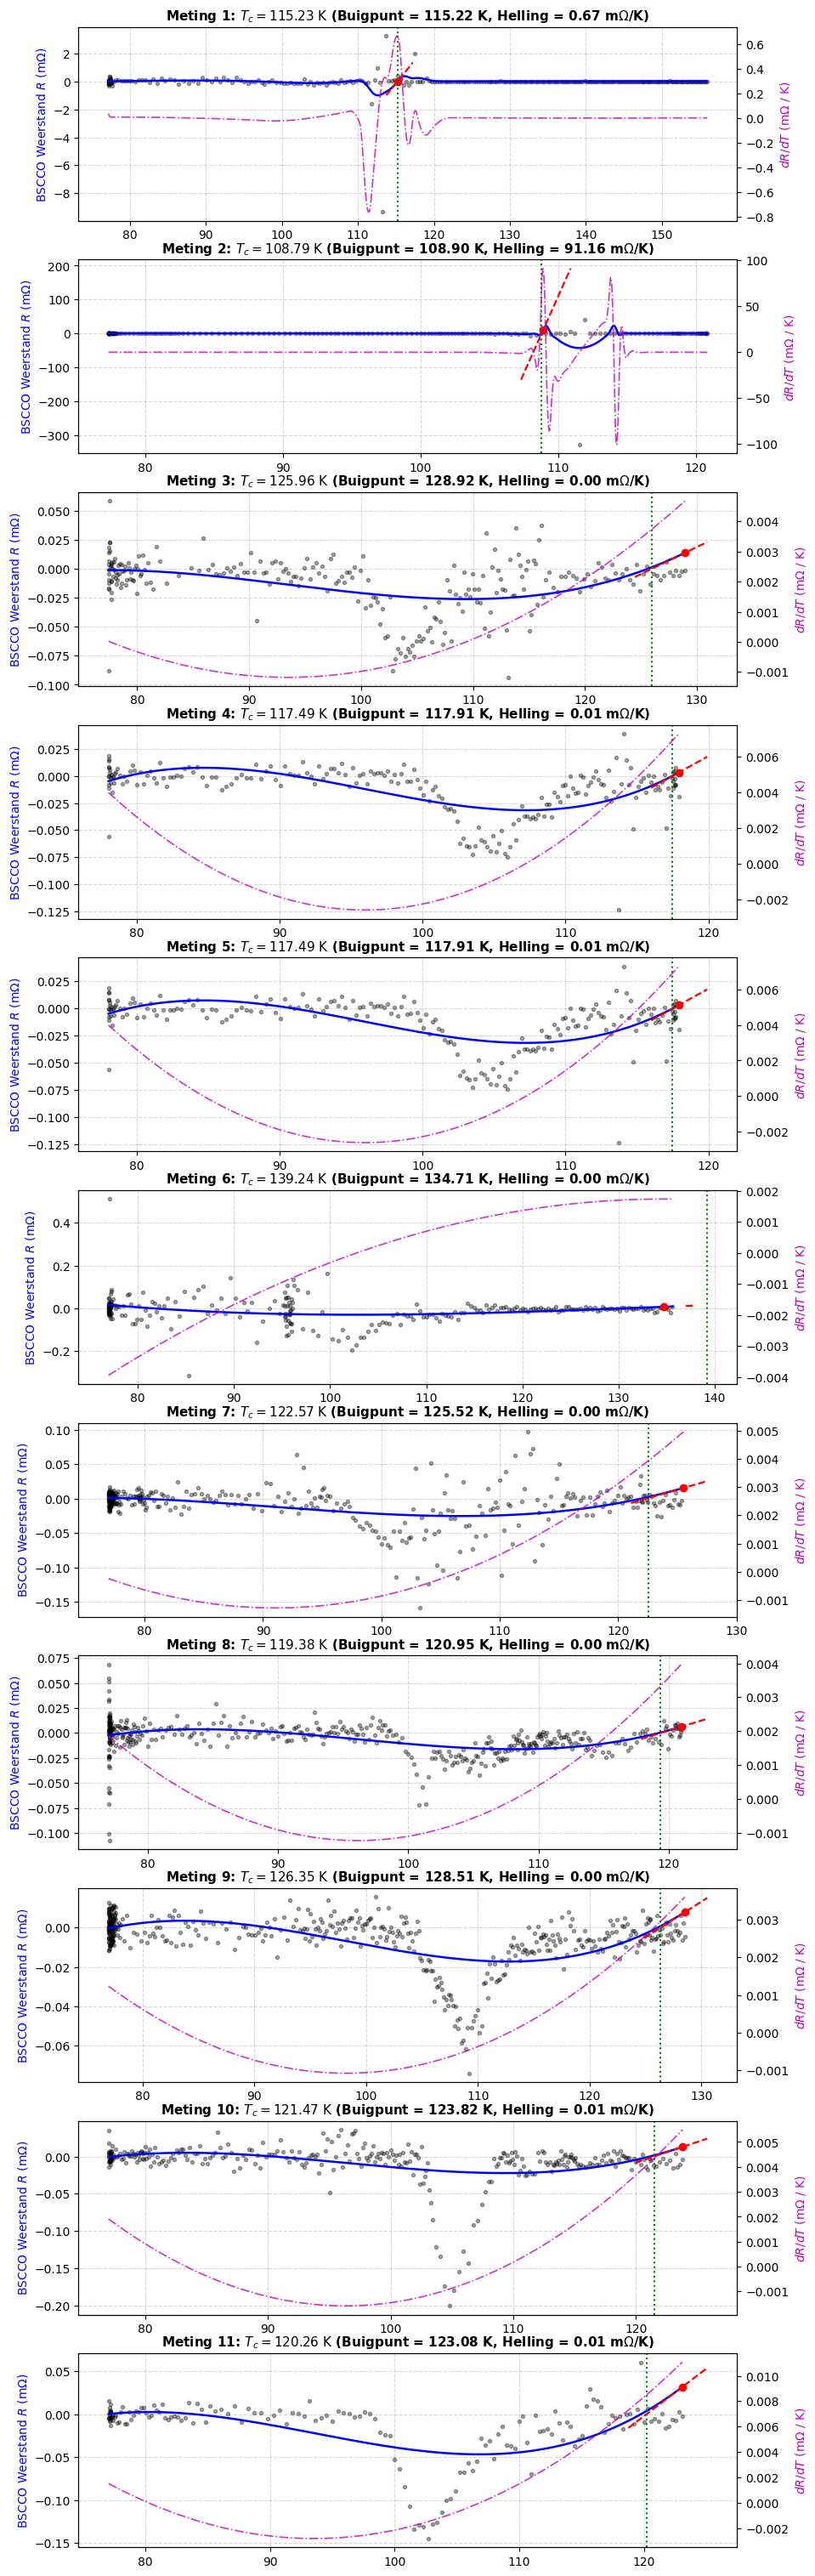

In [24]:
# ==========================================
# 5. VISUALISATIE: GRAFIEKEN MET FORMULE 4.4
# ==========================================
# Deze cel maakt gebruik van de ingelezen data en functies uit cel 1

# Eerst verzamelen we alle geldige meetparen
valid_pairs = []
for i in range(1, 13):
  smu_file = f'SMUdata_pt1000_{i}.csv'
  dmm_file = f'DMMdata_pt1000_{i}.csv'
  if os.path.exists(smu_file) and os.path.exists(dmm_file):
    V_check = load_lab_csv(smu_file)
    R_check = load_lab_csv(dmm_file)
    if len(V_check) >= 4 and len(R_check) >= 4:
      valid_pairs.append((i, smu_file, dmm_file))

num_plots = len(valid_pairs)

if num_plots > 0:
  fig, axes = plt.subplots(
      num_plots, 1, figsize=(10, 3.5 * num_plots), sharex=False
  )
  if num_plots == 1:
    axes = [axes]

  for idx, (i, smu_file, dmm_file) in enumerate(valid_pairs):
    R_pt1000_raw = load_lab_csv(dmm_file)
    V_raw = load_lab_csv(smu_file)

    # Paarsgewijze even lengte maken
    if len(V_raw) % 2 != 0:
      min_len = (len(V_raw) // 2) * 2
      V_raw = V_raw[:min_len]
      R_pt1000_raw = R_pt1000_raw[:min_len]

    # Formule (4.4) opsplitsing: V_M+ (+0.1 A) en V_M- (-0.1 A)
    V_M_pos = V_raw[0::2]
    V_M_neg = V_raw[1::2]
    R_pt1000_pairs = (R_pt1000_raw[0::2] + R_pt1000_raw[1::2]) / 2.0

    # Formule (4.4): V_M = (V_M+ - V_M-) / 2  -->  R = V_M / I
    V_M = (V_M_pos - V_M_neg) / 2.0
    R_bscco = V_M / I

    # Temperatuur omrekenen naar Kelvin
    T_data = pt1000_to_kelvin(R_pt1000_pairs)

    # Sorteren op stijgende temperatuur
    sort_idx = np.argsort(T_data)
    T_clean = T_data[sort_idx]
    R_clean = R_bscco[sort_idx]

    # Ruisfiltering & Spline Fit
    window_len = (
        15
        if len(R_clean) >= 15
        else (len(R_clean) if len(R_clean) % 2 != 0 else len(R_clean) - 1)
    )
    R_smooth = savgol_filter(R_clean, window_length=window_len, polyorder=2)

    spline = UnivariateSpline(T_clean, R_smooth, s=1e-6)
    T_fine = np.linspace(T_clean.min(), T_clean.max(), 3000)
    R_fit = spline(T_fine)
    dR_dT = spline.derivative(n=1)(T_fine)

    # Buigpunt & Tc Extrapolatie
    idx_max = np.argmax(dR_dT)
    T_inflection = T_fine[idx_max]
    R_inflection = R_fit[idx_max]
    m_max = dR_dT[idx_max]

    R_offset = np.mean(R_fit[:30]) if np.mean(R_fit[:30]) > 0 else 0.0
    Tc_extrapolated = T_inflection - ((R_inflection - R_offset) / m_max)

    # Raaklijn opstellen rond het buigpunt
    T_tangent = np.linspace(Tc_extrapolated - 1.5, T_inflection + 2.0, 200)
    R_tangent = m_max * (T_tangent - T_inflection) + R_inflection

    # Assen configureren
    ax1 = axes[idx]
    ax2 = ax1.twinx()  # Rechter as voor dR/dT

    # Linker as: Weerstand, Spline Fit & Raaklijn
    l1 = ax1.plot(
        T_clean,
        R_clean * 1000,
        'k.',
        alpha=0.35,
        label='Gecorrigeerde data (Formule 4.4)',
    )
    l2 = ax1.plot(
        T_fine,
        R_fit * 1000,
        'b-',
        linewidth=1.8,
        label='Spline Fit $R(T)$',
    )
    l3 = ax1.plot(
        T_tangent,
        R_tangent * 1000,
        'r--',
        linewidth=1.6,
        label=f'Raaklijn ($m={m_max*1000:.2f}\ \mathrm{{m\Omega/K}}$)',
    )
    ax1.plot(
        T_inflection,
        R_inflection * 1000,
        'ro',
        markersize=6,
        label=f'Buigpunt ({T_inflection:.2f} K)',
    )
    ax1.axvline(
        x=Tc_extrapolated,
        color='g',
        linestyle=':',
        linewidth=1.5,
        label=f'$T_c = {Tc_extrapolated:.2f}$ K',
    )

    # Rechter as: Eerste afgeleide dR/dT
    l4 = ax2.plot(
        T_fine,
        dR_dT * 1000,
        'm-.',
        linewidth=1.2,
        alpha=0.8,
        label='1e Afgeleide $dR/dT$',
    )

    # Opmaak per subgrafiek
    ax1.set_ylabel('BSCCO Weerstand $R$ (m$\Omega$)', color='b', fontsize=10)
    ax2.set_ylabel('$dR/dT$ (m$\Omega$ / K)', color='m', fontsize=10)
    ax1.set_title(
        f'Meting {i}: $T_c = {Tc_extrapolated:.2f}\ \mathrm{{K}}$ (Buigpunt ='
        f' {T_inflection:.2f} K, Helling = {m_max*1000:.2f} m$\Omega$/K)',
        fontsize=11,
        fontweight='bold',
    )
    ax1.grid(True, linestyle='--', alpha=0.5)